# Synthetic global rock-application schedules

Builds three **new** global rock-amendment schedules -- `early`, `central`, `late` -- each an S-curve (logistic) ramp, differing in inflection-point timing (`t0`) and growth rate/smoothness (`k`). `SCHEDULE_MODE` picks what the curves are anchored to:

- `same_total` -- all curves share the same **cumulative rock mass** (integrated 2020-2100), just reaching that total on different timelines.
- `same_max` -- all curves approach the same **asymptotic peak deployment rate**, at different inflection times and growth rates, so their cumulative totals differ.

Output is saved in the same `dfrock`/`dsag` pkl+zarr format used by the existing GCAM schedules (`exe_central1p5`, etc.), so the three new schedules can be dropped straight into `SCHEDULE_EXP_SETS` in `cdr-gcam-globalscaling-constApp-multiSchedule-COILED.ipynb`.

## Approach
Each global curve is the sum of 32 regional curves (`gcam_gross_cdr_mtCO2`, per GCAM region, per year -- this is the only column `cfp.gcam_postprocess_region_constApp` actually reads to build `M_GCAM`; the FIXED-apprate rate/area columns are unrelated to timing and stay put). Rather than inventing a new regional split from scratch, we:

1. Take an existing schedule (`BASE_SCHEDULE`) as the donor for the **regional split** -- i.e. what fraction of the global total each of the 32 regions gets, at each point in time.
2. Define a synthetic **global** target curve (S-curve, either fixed-total or fixed-max depending on `SCHEDULE_MODE`).
3. Compute a per-year rescaling factor: `factor(t) = target_global(t) / donor_global(t)`.
4. Apply that *same* factor to every region's donor curve at time `t`. Since `donor_global(t) = sum_regions(donor_region(t))`, multiplying every region by the same `factor(t)` guarantees the rescaled regions sum back exactly to `target_global(t)` -- this is the invariant we verify with a plot below, not just assume.

Only `gcam_gross_cdr_mtCO2` and its three FIXED-apprate-derived diagnostic columns (`cropland_area_required_ha`, `cropland_fraction_required`, `cropland_fraction_effective` -- all linear in the mass since the application *rate* is held fixed) get rescaled. `rockflx_Mt`, `rockflx_Mt_ha`, `rockflx_t_ha`, `effective_rate_t_ha` describe the fixed per-hectare recipe at the representative pixel and are untouched.

In [3]:
import os

from itertools import product
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import s3fs
import xarray as xr

## Config

In [ ]:
# --- [ donor schedule: supplies the 32-region *split*, rescaled at each timestep ] ---
BASE_SCHEDULE = 'exe_central1p5'
RUN_FORMAT    = 'one-cell-per-region'
DEG_RES       = 1

# --- [ representative SCEPTER run this is destined for -- used only to auto-detect which
#       apprate_base value(s) need a matching dfrock/dsag pair ] ---
EXP_GROUP = 'gcam_opr_full_cec1'
EXP_SET   = 'exe_central1p5'
SAVE_GROUP = 'gcam'
idx = '001'

# shared cumulative total (integrated 2020-2100) all three schedules must hit, expressed as a
# multiple of BASE_SCHEDULE's own cumulative total -- 1 = same total as BASE_SCHEDULE, 0.5 =
# half, 2 = double, etc. Only used when SCHEDULE_MODE == 'same_total'.
TARGET_CUMULATIVE_FACTOR = 0.5

# shared asymptotic peak deployment rate (Mt CO2/yr) all three curves approach as t -> inf.
# Only used when SCHEDULE_MODE == 'same_max'. 
TARGET_MAX_MTCO2 = 2000.0

# --- [ what the synthetic curves are anchored to --
#       'same_total' -- all curves share the same cumulative total (2020-2100), reaching it on
#                        different timelines (set via TARGET_CUMULATIVE_FACTOR below)
#       'same_max'   -- all curves approach the same asymptotic peak rate (set via
#                        TARGET_MAX_MTCO2 below), at different inflection times/growth rates ] ---
SCHEDULE_MODE = 'same_max'  # 'same_total' or 'same_max'

# --- [ new synthetic schedules: name -> logistic (t0=inflection year, k=steepness per year --
#       larger k = faster/sharper ramp, smaller k = slower/smoother ramp) ] ---
NEW_SCHEDULES = {
    f'scurve_{TARGET_MAX_MTCO2/1e3}Gt_early':   dict(t0=2040, k=0.2),
    f'scurve_{TARGET_MAX_MTCO2/1e3}Gt_mid':     dict(t0=2060, k=0.2),
    f'scurve_{TARGET_MAX_MTCO2/1e3}Gt_late':    dict(t0=2085, k=0.2),
}
# --- [ or if you want to generate across a wider range of outcomes (all combinations) ]
# t0_values = np.linspace(2035, 2090, 4)
# k_values  = np.array([0.02, 0.05, 0.1, 0.2, 0.5]) # np.linspace(0.1, 0.6, 9)
# NEW_SCHEDULES = {
#     f"synthetic_scurve_t0_{t0:.2f}_k_{k:.2f}": {"t0": t0, "k": k}
#     for t0, k in product(t0_values, k_values)
# }

# --- [ where the target S-curves come from --
#       'internal'  -- build them right here via build_scurve_fixed_total/build_scurve_fixed_max
#                       from NEW_SCHEDULES + SCHEDULE_MODE above (original behavior, unchanged)
#       's3_matrix' -- read precomputed (L, C0, k, t0) curves from create-synthetic-s-curves.ipynb's
#                       S3 output instead (one CSV per case + a manifest.csv describing each) ] ---
CURVE_SOURCE = 's3_matrix'  # 'internal' or 's3_matrix'

# --- [ only used when CURVE_SOURCE == 's3_matrix' ] ---
SYNTHETIC_MATRIX_S3_DIR = ('s3://carbonplan-carbon-removal/ew-workflows-data/gcam/apprate_calculated/'
                            'one-cell-per-region/synthetic-rateConstrained')
#
# SCHEDULE_NAMES_TO_RUN = 'all' # ['cdrfyi-sales_k_gcam_L2.0Gt', 'nearterm-gcam-first10yrs_k_nemetMedian_L0.5Gt']
# SCHEDULE_NAMES_TO_RUN = ['nearterm-gcam-first10yrs_k_nemetMedian_L0.5Gt', 'nearterm-gcam-first10yrs_k_gcam_L_gcam',
#                          'nearterm-gcam-first10yrs_k_gcam_L0.5Gt', 'nearterm-gcam-first10yrs_k_gcam_L2.0Gt',
#                          'nearterm-gcam-first10yrs_k_nemetMedian_L_gcam', 'nearterm-gcam-first10yrs_k_nemetMedian_L2.0Gt']
SCHEDULE_NAMES_TO_RUN = ['gcam-native_L0.5Gt']

RCO2_GCAM = 0.3  # tCO2 / t basalt, same constant used elsewhere in this repo

# --- [ where to write the result ] ---
SAVE_TO_S3 = True
# if False, the save cell refuses to write (and lists the conflicts) when any destination
# schedule/apprate already has a rock_fn on S3, instead of silently overwriting it
OVERWRITE_EXISTING = False
S3_BASE = f's3://carbonplan-carbon-removal/ew-workflows-data/gcam/apprate_calculated/{RUN_FORMAT}'
rock_fn = f'annual_rockflx_densest-ag-region_{DEG_RES}deg.pkl'
ag_fn   = f'cropland+gcamRegions_time_{DEG_RES}deg.zarr'

## Auto-detect which apprate(s) need a synthetic dfrock/dsag pair
Mirrors `apprates_arr = np.unique(ds.apprate_base.values)` in the multiSchedule-COILED notebook.

In [5]:
datpath = f"s3://carbonplan-carbon-removal/ew-workflows-data/scepter/postprocessed/{SAVE_GROUP}/{EXP_GROUP}/{EXP_SET}_{idx}"
ds_rep_meta = xr.open_zarr(os.path.join(datpath, 'ds_cdr.zarr'))
APPRATES_NEEDED = sorted(np.unique(ds_rep_meta.apprate_base.values).tolist())
print('apprates needed:', APPRATES_NEEDED)

apprates needed: [0.1, 0.25, 0.5, 1.0, 2.5, 5.0, 10.0, 20.0, 30.0]


## Read in the donor schedule's regional split
Read one `dfrock` per apprate.

In [6]:
dfrock_base_byApprate = {}
for apprate in APPRATES_NEEDED:
    apprate_name = f'{apprate}-tHaYr-appRate-FIXED'
    gcam_dir = f'{S3_BASE}/{BASE_SCHEDULE}/{apprate_name}'
    dfrock_base_byApprate[apprate_name] = pd.read_pickle(os.path.join(gcam_dir, rock_fn))

# sanity check: gcam_gross_cdr_mtCO2 should be identical across apprates (only the
# fixed-rate/area columns should differ) -- if this ever fails, the fitting below needs
# to be redone per-apprate instead of once.
apprate_names = list(dfrock_base_byApprate.keys())
if len(apprate_names) > 1:
    ref = dfrock_base_byApprate[apprate_names[0]].set_index(['region_nospaces', 'time'])['gcam_gross_cdr_mtCO2']
    for name in apprate_names[1:]:
        other = dfrock_base_byApprate[name].set_index(['region_nospaces', 'time'])['gcam_gross_cdr_mtCO2']
        assert np.allclose(ref, other), f'gcam_gross_cdr_mtCO2 differs between apprates ({apprate_names[0]} vs {name}) -- fitting logic below assumes it does not'
    print('confirmed: gcam_gross_cdr_mtCO2 is apprate-invariant across', apprate_names)

df_base = dfrock_base_byApprate[apprate_names[0]]
years = np.sort(df_base['time'].unique()).astype(float)
n_regions = df_base['region_nospaces'].nunique()
print(f'{n_regions} regions, years {years.min():.0f}-{years.max():.0f}')

confirmed: gcam_gross_cdr_mtCO2 is apprate-invariant across ['0.1-tHaYr-appRate-FIXED', '0.25-tHaYr-appRate-FIXED', '0.5-tHaYr-appRate-FIXED', '1.0-tHaYr-appRate-FIXED', '2.5-tHaYr-appRate-FIXED', '5.0-tHaYr-appRate-FIXED', '10.0-tHaYr-appRate-FIXED', '20.0-tHaYr-appRate-FIXED', '30.0-tHaYr-appRate-FIXED']
32 regions, years 2020-2100


exe_central1p5 global cumulative total: 282,193 Mt CO2 (940,644 Mt rock)


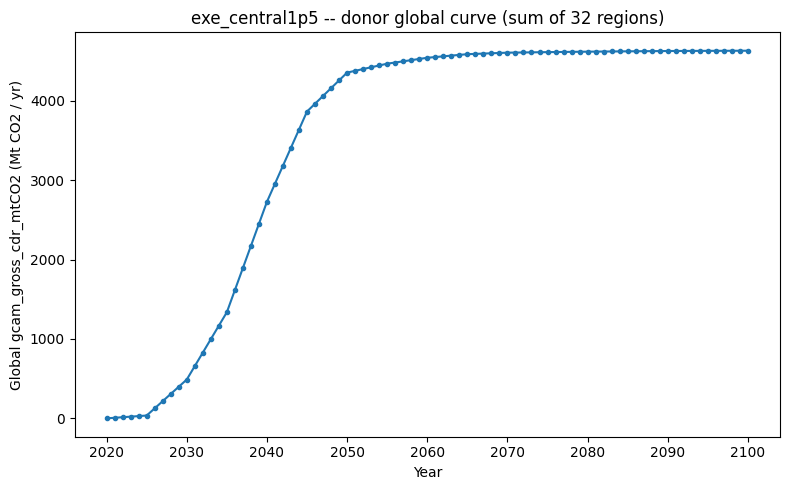

In [7]:
baseline_global = (
    df_base.groupby('time')['gcam_gross_cdr_mtCO2'].sum().reindex(years).values
)
baseline_total_mtco2 = np.trapezoid(baseline_global, years)
print(f'{BASE_SCHEDULE} global cumulative total: {baseline_total_mtco2:,.0f} Mt CO2 '
      f'({baseline_total_mtco2 / RCO2_GCAM:,.0f} Mt rock)')

plt.figure(figsize=(8, 5))
plt.plot(years, baseline_global, marker='o', ms=3)
plt.xlabel('Year')
plt.ylabel('Global gcam_gross_cdr_mtCO2 (Mt CO2 / yr)')
plt.title(f'{BASE_SCHEDULE} -- donor global curve (sum of 32 regions)')
plt.tight_layout()
plt.show()

## Build (or read in) the target synthetic S-curves
`CURVE_SOURCE` picks where these come from:

- `internal` -- logistic `raw(t) = 1 / (1 + exp(-k*(t - t0)))`, anchored so `raw(2020) = 0` (matches the donor's own 2020 = 0 starting point). What it's then scaled to depends on `SCHEDULE_MODE`:
  - `same_total` -- scaled so its integral over the full window hits `target_cumulative`.
  - `same_max` -- scaled so its asymptote (`raw -> 1` as `t -> inf`, not just `curve.max()` within 2020-2100) hits `TARGET_MAX_MTCO2`. A late `t0` combined with a small `k` can mean the in-window peak still falls noticeably short of that asymptote -- worth checking against the printed `peak` values below.
- `s3_matrix` -- reads already-fully-specified `(C0, L, k, t0)` curves from `create-synthetic-s-curves.ipynb`'s S3 output (`SYNTHETIC_MATRIX_S3_DIR`), selecting just the `SCHEDULE_NAMES_TO_RUN` entries from its `manifest.csv`. Each curve already has its own independent asymptote `L` baked in, so there's no shared `SCHEDULE_MODE` target to reconcile against here. Unlike `internal`, these curves are anchored to a real-world `(C0, t0)` reference point rather than to zero at 2020.

In [8]:
if CURVE_SOURCE == 'internal':
    def build_scurve_fixed_total(years, t0, k, target_cumulative):
        raw = 1.0 / (1.0 + np.exp(-k * (years - t0)))
        raw0 = np.clip(raw - raw[0], 0, None)  # anchor to ~0 at years[0]
        shape_area = np.trapezoid(raw0, years)
        return raw0 * (target_cumulative / shape_area)


    def build_scurve_fixed_max(years, t0, k, target_max):
        raw = 1.0 / (1.0 + np.exp(-k * (years - t0)))
        raw0 = np.clip(raw - raw[0], 0, None)  # anchor to ~0 at years[0]
        asymptote = 1.0 - raw[0]  # raw -> 1 as t -> inf, so raw0 -> this asymptote
        return raw0 * (target_max / asymptote)


    # suffix schedule names by mode so re-running under a different SCHEDULE_MODE doesn't
    # silently overwrite an earlier mode's S3 output at the same {schedule_name}/{apprate} path
    MODE_SUFFIXES = {'same_total': '_sameTotal', 'same_max': '_sameMax'}
    if SCHEDULE_MODE not in MODE_SUFFIXES:
        raise ValueError(f"unknown SCHEDULE_MODE: {SCHEDULE_MODE!r} (expected 'same_total' or 'same_max')")
    schedule_names = {base_name: f'{base_name}{MODE_SUFFIXES[SCHEDULE_MODE]}' for base_name in NEW_SCHEDULES}

    if SCHEDULE_MODE == 'same_total':
        target_cumulative = baseline_total_mtco2 * TARGET_CUMULATIVE_FACTOR
        synthetic_curves = {
            schedule_names[base_name]: build_scurve_fixed_total(years, p['t0'], p['k'], target_cumulative)
            for base_name, p in NEW_SCHEDULES.items()
        }
    else:
        synthetic_curves = {
            schedule_names[base_name]: build_scurve_fixed_max(years, p['t0'], p['k'], TARGET_MAX_MTCO2)
            for base_name, p in NEW_SCHEDULES.items()
        }

    for base_name, params in NEW_SCHEDULES.items():
        full_name = schedule_names[base_name]
        curve = synthetic_curves[full_name]
        total = np.trapezoid(curve, years)
        print(f'{full_name:34s} t0={params["t0"]}  k={params["k"]}  peak={curve.max():8.1f} Mt CO2/yr  '
              f'total={total:,.0f} Mt CO2')

elif CURVE_SOURCE == 's3_matrix':
    manifest = pd.read_csv(f'{SYNTHETIC_MATRIX_S3_DIR}/manifest.csv', index_col='schedule_name')

    if SCHEDULE_NAMES_TO_RUN == 'all':
        names_to_run = manifest.index.tolist()
    else:
        missing = [name for name in SCHEDULE_NAMES_TO_RUN if name not in manifest.index]
        if missing:
            raise KeyError(f'requested schedule name(s) not found in {SYNTHETIC_MATRIX_S3_DIR}/manifest.csv: {missing}')
        names_to_run = list(SCHEDULE_NAMES_TO_RUN)

    synthetic_curves = {}
    for name in names_to_run:
        curve_df = pd.read_csv(f'{SYNTHETIC_MATRIX_S3_DIR}/{name}.csv', index_col='year')
        curve = curve_df['value_mtco2_per_yr'].reindex(years).values
        # the rescaling step below multiplies every region by one shared factor(t) =
        # target(t)/donor(t) -- that can't produce a nonzero result wherever the donor is
        # exactly zero (year 2020, confirmed the only such year -- see markdown above), so force
        # the target to match there too. Every other year, including the curve's true C0 anchor,
        # is left untouched.
        curve = np.where(baseline_global == 0, 0.0, curve)
        synthetic_curves[name] = curve

    for name in names_to_run:
        p = manifest.loc[name]
        curve = synthetic_curves[name]
        total = np.trapezoid(curve, years)
        print(f'{name:45s} C0={p["C0"]:>10,.2f}  L={p["L"]:>10,.2f}  k={p["k"]:.3f}  t0={p["t0"]:.0f}  '
              f'peak={curve.max():>10,.1f} Mt CO2/yr  total={total:>12,.0f} Mt CO2')

else:
    raise ValueError(f"unknown CURVE_SOURCE: {CURVE_SOURCE!r} (expected 'internal' or 's3_matrix')")

gcam-native_L0.5Gt                            C0=     23.04  L=    500.00  k=0.240  t0=2026  peak=     500.0 Mt CO2/yr  total=      30,469 Mt CO2


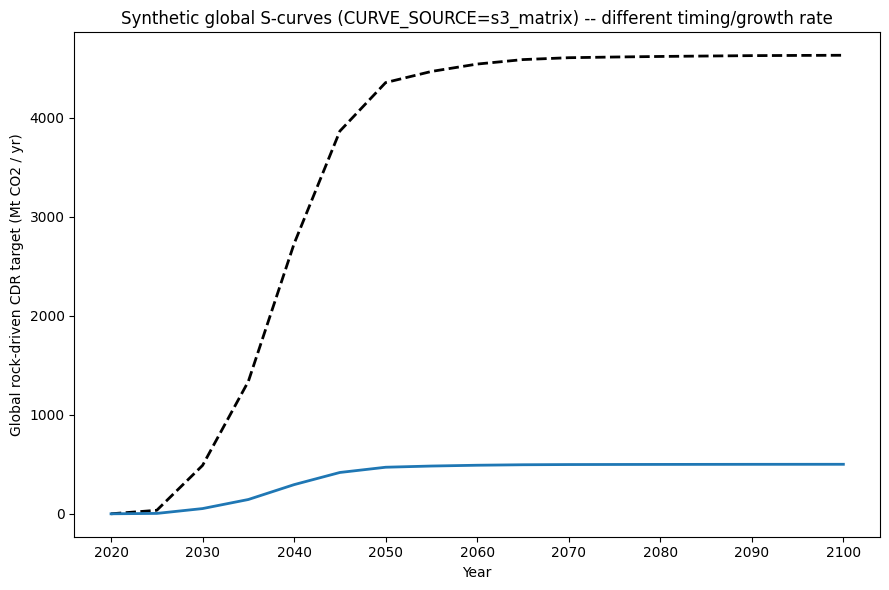

Peaks and cumulative totals (s3_matrix mode -- each curve has its own L, no shared target):
  gcam-native_L0.5Gt                            peak=500 Mt CO2/yr  cumulative=30,469 Mt CO2


In [9]:
plt.figure(figsize=(9, 6))
plt.plot(years, baseline_global, 'k--', label=f'{BASE_SCHEDULE} (donor)', lw=2)
for name, curve in synthetic_curves.items():
    plt.plot(years, curve, label=name, lw=2)
plt.xlabel('Year')
plt.ylabel('Global rock-driven CDR target (Mt CO2 / yr)')
plt.title(f'Synthetic global S-curves (CURVE_SOURCE={CURVE_SOURCE}) -- different timing/growth rate')
# plt.legend()
plt.tight_layout()
plt.show()

if CURVE_SOURCE == 'internal' and SCHEDULE_MODE == 'same_total':
    print(f'Cumulative totals (should all match target = {TARGET_CUMULATIVE_FACTOR}x {BASE_SCHEDULE}):')
    print(f'  {BASE_SCHEDULE:28s} {baseline_total_mtco2:,.0f} Mt CO2  (1.00x)')
    for name, curve in synthetic_curves.items():
        total = np.trapezoid(curve, years)
        print(f'  {name:28s} {total:,.0f} Mt CO2  ({total / baseline_total_mtco2:.2f}x)')
elif CURVE_SOURCE == 'internal':  # same_max
    print(f'Peaks (asymptote target = {TARGET_MAX_MTCO2:,.0f} Mt CO2/yr as t -> inf; '
          f'in-window max may fall short of that for a late/slow curve):')
    for name, curve in synthetic_curves.items():
        total = np.trapezoid(curve, years)
        print(f'  {name:28s} in-window max={curve.max():,.0f} Mt CO2/yr  '
              f'cumulative={total:,.0f} Mt CO2')
else:  # s3_matrix -- each curve already has its own independent L, no single shared target
    print('Peaks and cumulative totals (s3_matrix mode -- each curve has its own L, no shared target):')
    for name, curve in synthetic_curves.items():
        total = np.trapezoid(curve, years)
        print(f'  {name:45s} peak={curve.max():,.0f} Mt CO2/yr  cumulative={total:,.0f} Mt CO2')

## Per-year rescaling factor
`factor(t) = target_global(t) / donor_global(t)`, applied uniformly to every region at time `t`. Watch for factor spikes in early years, where the donor curve is still near zero -- a large factor there just means "the synthetic curve wants meaningful deployment earlier than the donor scenario has any," which is expected for the `early` schedule.

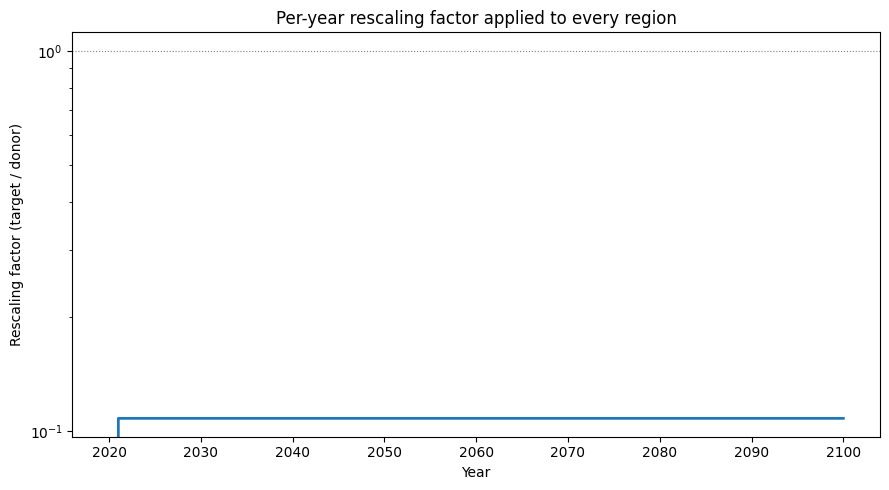

gcam-native_L0.5Gt           max factor = 0.11x at year 2022


In [10]:
EPS = 1e-6  # Mt CO2/yr -- below this, treat donor as zero to avoid divide-by-zero

factors = {}
for name, curve in synthetic_curves.items():
    factor = np.where(baseline_global > EPS, curve / np.where(baseline_global > EPS, baseline_global, 1.0), 0.0)
    factors[name] = factor

plt.figure(figsize=(9, 5))
for name, factor in factors.items():
    plt.plot(years, factor, label=name, lw=2)
plt.axhline(1.0, color='gray', lw=0.8, ls=':')
plt.xlabel('Year')
plt.ylabel('Rescaling factor (target / donor)')
plt.title('Per-year rescaling factor applied to every region')
plt.yscale('log')
# plt.legend()
plt.tight_layout()
plt.show()

for name, factor in factors.items():
    i = np.argmax(factor)
    print(f'{name:28s} max factor = {factor[i]:.2f}x at year {years[i]:.0f}'
          + ('  <-- check this' if factor[i] > 20 else ''))

## Apply the factor to every region, for every apprate needed
Rescales the four mass-derived columns (`gcam_gross_cdr_mtCO2`, `cropland_area_required_ha`, `cropland_fraction_required`, `cropland_fraction_effective`); everything else (rate, area, lat/lon, ids) is copied through unchanged.

In [11]:
MASS_DERIVED_COLS = [
    'gcam_gross_cdr_mtCO2', 'cropland_area_required_ha',
    'cropland_fraction_required', 'cropland_fraction_effective',
]

def build_synthetic_dfrock(df_donor, factor, years):
    factor_series = pd.Series(factor, index=years, name='factor')
    df_new = df_donor.merge(factor_series, left_on='time', right_index=True, how='left')
    for col in MASS_DERIVED_COLS:
        df_new[col] = df_new[col] * df_new['factor']
    return df_new.drop(columns=['factor'])


dfrock_synthetic = {}  # {schedule_name: {apprate_name: df}}
for name, factor in factors.items():
    dfrock_synthetic[name] = {
        apprate_name: build_synthetic_dfrock(df_donor, factor, years)
        for apprate_name, df_donor in dfrock_base_byApprate.items()
    }

## Validate
Sum the rescaled regions back up and confirm they reproduce the target curve exactly (this is the core assumption behind the whole approach -- verify it, don't just trust it), check for NaNs/negatives, and spot-check a few individual regions.

In [12]:
ref_apprate_name = apprate_names[0]

for name, curve in synthetic_curves.items():
    df_new = dfrock_synthetic[name][ref_apprate_name]
    check_global = df_new.groupby('time')['gcam_gross_cdr_mtCO2'].sum().reindex(years).values
    max_abs_err = np.nanmax(np.abs(check_global - curve))
    n_neg = (df_new[MASS_DERIVED_COLS] < -1e-6).any(axis=1).sum()
    n_nan = df_new[MASS_DERIVED_COLS].isna().any(axis=1).sum()
    rate_unchanged = np.allclose(
        df_new[['rockflx_Mt', 'effective_rate_t_ha']].values,
        dfrock_base_byApprate[ref_apprate_name][['rockflx_Mt', 'effective_rate_t_ha']].values,
    )
    status = 'OK' if (max_abs_err < 1e-6 and n_neg == 0 and n_nan == 0 and rate_unchanged) else 'CHECK THIS'
    print(f'[{name}] max err vs target={max_abs_err:.2e}  negatives={n_neg}  NaNs={n_nan}  '
          f'rate/area-recipe unchanged={rate_unchanged}  -> {status}')

[gcam-native_L0.5Gt] max err vs target=5.68e-14  negatives=0  NaNs=0  rate/area-recipe unchanged=True  -> OK


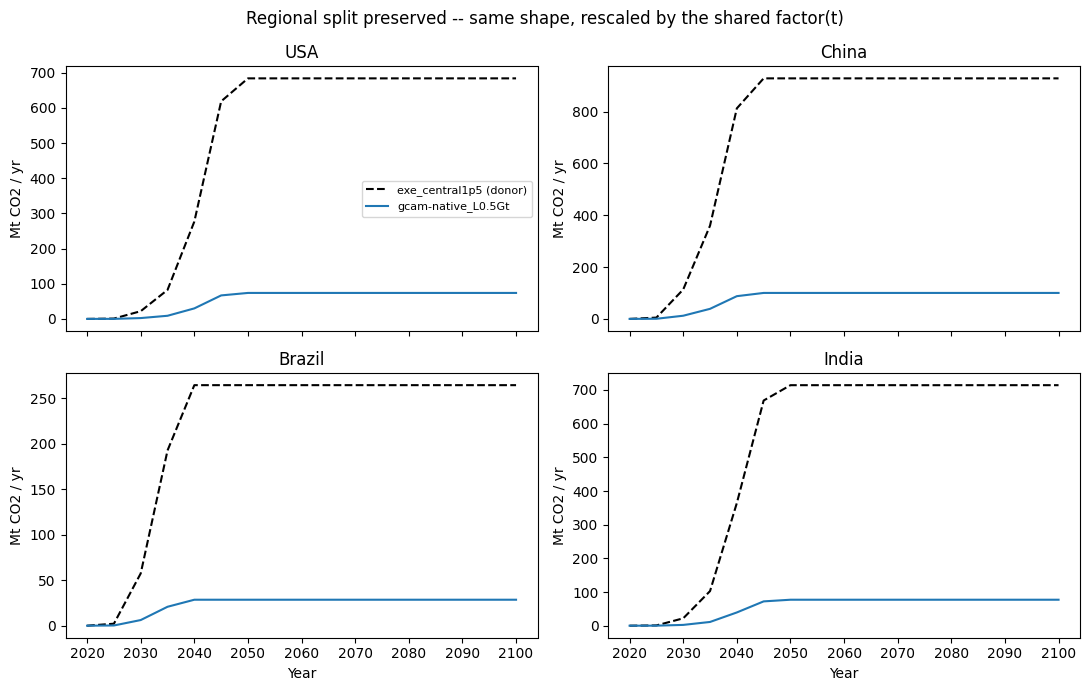

In [13]:
# spot-check a handful of individual regions
regions_to_check = ['USA', 'China', 'Brazil', 'India']

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for ax, region in zip(axes.flat, regions_to_check):
    donor_region = (
        df_base[df_base['region_nospaces'] == region]
        .sort_values('time')['gcam_gross_cdr_mtCO2'].values
    )
    ax.plot(years, donor_region, 'k--', label=f'{BASE_SCHEDULE} (donor)', lw=1.5)
    for name in synthetic_curves:
        df_new = dfrock_synthetic[name][ref_apprate_name]
        region_curve = (
            df_new[df_new['region_nospaces'] == region]
            .sort_values('time')['gcam_gross_cdr_mtCO2'].values
        )
        ax.plot(years, region_curve, label=name, lw=1.5)
    ax.set_title(region)
    ax.set_ylabel('Mt CO2 / yr')
axes[0, 0].legend(fontsize=8)
for ax in axes[-1, :]:
    ax.set_xlabel('Year')
fig.suptitle('Regional split preserved -- same shape, rescaled by the shared factor(t)')
fig.tight_layout()
plt.show()

## Save
Writes each schedule's `dfrock` pkl (rescaled) and copies the donor's `dsag` cropland-map zarr unchanged (it's a physical land-area dataset, invariant to the timing scenario) to:

`s3://carbonplan-carbon-removal/ew-workflows-data/gcam/apprate_calculated/one-cell-per-region/{schedule}/{apprate}-tHaYr-appRate-FIXED/`

so these can be added directly to `SCHEDULE_EXP_SETS` in `cdr-gcam-globalscaling-constApp-multiSchedule-COILED.ipynb`.

In [14]:
fs = s3fs.S3FileSystem()

if SAVE_TO_S3:
    # check *before* writing anything, so a conflict on schedule #3 can't leave #1 and #2
    # half-overwritten
    if not OVERWRITE_EXISTING:
        existing = [
            f'{schedule_name}/{apprate_name}'
            for schedule_name, df_by_apprate in dfrock_synthetic.items()
            for apprate_name in df_by_apprate
            if fs.exists(f'{S3_BASE}/{schedule_name}/{apprate_name}/{rock_fn}'.replace('s3://', ''))
        ]
        if existing:
            raise FileExistsError(
                'refusing to overwrite existing S3 output (set OVERWRITE_EXISTING = True to '
                f'proceed anyway):\n  ' + '\n  '.join(existing)
            )

    for schedule_name, df_by_apprate in dfrock_synthetic.items():
        for apprate_name, df_new in df_by_apprate.items():
            dst_dir = f'{S3_BASE}/{schedule_name}/{apprate_name}'

            # --- pkl (rescaled) ---
            df_new.to_pickle(os.path.join(dst_dir, rock_fn))

            # --- zarr (unchanged donor cropland map, copied as-is) ---
            src_zarr = f'{S3_BASE}/{BASE_SCHEDULE}/{apprate_name}/{ag_fn}'
            dst_zarr = f'{dst_dir}/{ag_fn}'
            fs.copy(src_zarr.replace('s3://', ''), dst_zarr.replace('s3://', ''), recursive=True)

            print(f'saved {schedule_name}/{apprate_name}')
else:
    print('SAVE_TO_S3 is False -- nothing written. Flip it to True once the plots above look right.')

print()
print('Add to SCHEDULE_EXP_SETS in cdr-gcam-globalscaling-constApp-multiSchedule-COILED.ipynb:')
print(list(dfrock_synthetic.keys()))

saved gcam-native_L0.5Gt/0.1-tHaYr-appRate-FIXED
saved gcam-native_L0.5Gt/0.25-tHaYr-appRate-FIXED
saved gcam-native_L0.5Gt/0.5-tHaYr-appRate-FIXED
saved gcam-native_L0.5Gt/1.0-tHaYr-appRate-FIXED
saved gcam-native_L0.5Gt/2.5-tHaYr-appRate-FIXED
saved gcam-native_L0.5Gt/5.0-tHaYr-appRate-FIXED
saved gcam-native_L0.5Gt/10.0-tHaYr-appRate-FIXED
saved gcam-native_L0.5Gt/20.0-tHaYr-appRate-FIXED
saved gcam-native_L0.5Gt/30.0-tHaYr-appRate-FIXED

Add to SCHEDULE_EXP_SETS in cdr-gcam-globalscaling-constApp-multiSchedule-COILED.ipynb:
['gcam-native_L0.5Gt']


## Round-trip read-back check

In [15]:
if SAVE_TO_S3:
    for schedule_name in dfrock_synthetic:
        for apprate_name in apprate_names:
            reload_dir = f'{S3_BASE}/{schedule_name}/{apprate_name}'
            df_reload = pd.read_pickle(os.path.join(reload_dir, rock_fn))
            expected = dfrock_synthetic[schedule_name][apprate_name]
            pd.testing.assert_frame_equal(
                df_reload.reset_index(drop=True), expected.reset_index(drop=True)
            )
            _ = xr.open_zarr(os.path.join(reload_dir, ag_fn))  # just confirm it opens
    print('round-trip check passed for all schedules/apprates')

round-trip check passed for all schedules/apprates


In [14]:
# -----